In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

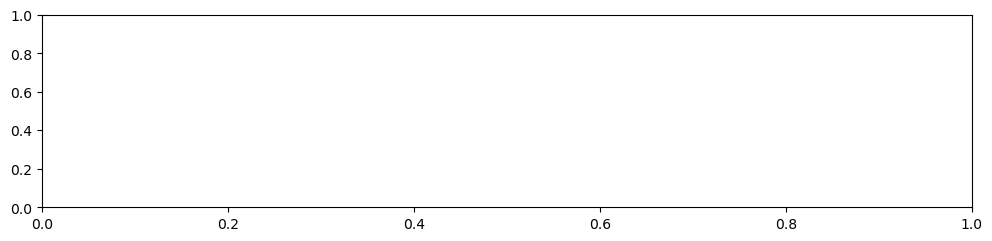

In [3]:
# --- paramètres ---
debut = pd.Timestamp("2023-07-26")
fin = pd.Timestamp("2025-06-29")
motif = [("train", 105), ("trou", 21), ("val", 21), ("trou", 21), ("test", 42), ("trou", 21)]
couleurs = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

# pour compter les jours de chaque jeu
jours = {"train": 0, "val": 0, "test": 0, "trou": 0}

fig, ax = plt.subplots(figsize=(12, 2.5))

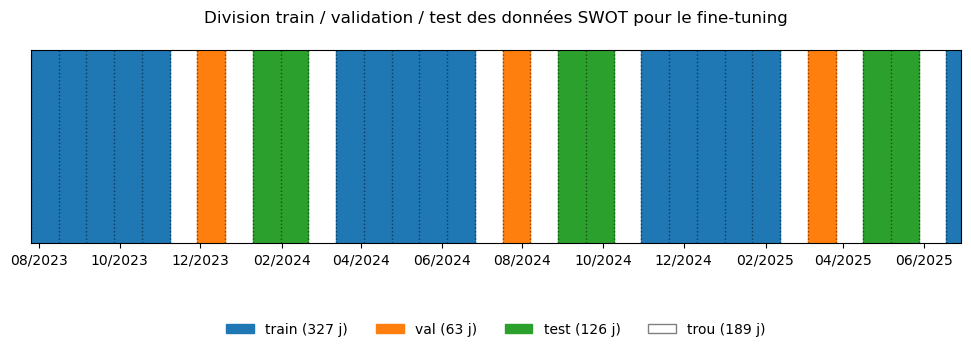

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

# --- paramètres ---
debut = pd.Timestamp("2023-07-26")
fin = pd.Timestamp("2025-06-29")
motif = [("train", 105), ("trou", 21), ("val", 21), ("trou", 21), ("test", 42), ("trou", 21)]
couleurs = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

# pour compter les jours de chaque jeu
jours = {"train": 0, "val": 0, "test": 0, "trou": 0}

fig, ax = plt.subplots(figsize=(12, 2.5))

# --- on avance bloc par bloc ---
date = debut
i = 0
while date <= fin:
    nom, duree = motif[i % len(motif)]          # bloc suivant du motif (on boucle)
    date_fin = min(date + pd.Timedelta(days=duree), fin + pd.Timedelta(days=1))

    if nom != "trou":                            # les trous restent blancs
        ax.axvspan(date, date_fin, color=couleurs[nom])

    jours[nom] += (date_fin - date).days
    date = date_fin
    i += 1

# --- cycles SWOT (21 j) en pointillés fins ---
date_cycle = debut
while date_cycle <= fin:
    ax.axvline(date_cycle, color="k", linestyle=":", linewidth=1, alpha=0.5)
    date_cycle = date_cycle + pd.Timedelta(days=21)
# --- légende avec le nombre de jours ---
legende = [Patch(color=couleurs[n], label=f"{n} ({jours[n]} j)") for n in couleurs]
legende.append(Patch(facecolor="white", edgecolor="grey", label=f"trou ({jours['trou']} j)"))
ax.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False)

# --- axes ---
ax.set_xlim(debut, fin)
ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("Division train / validation / test des données SWOT pour le fine-tuning", pad=20)

#plt.savefig("figures/division_dataset.png", dpi=200, bbox_inches="tight")
plt.show()

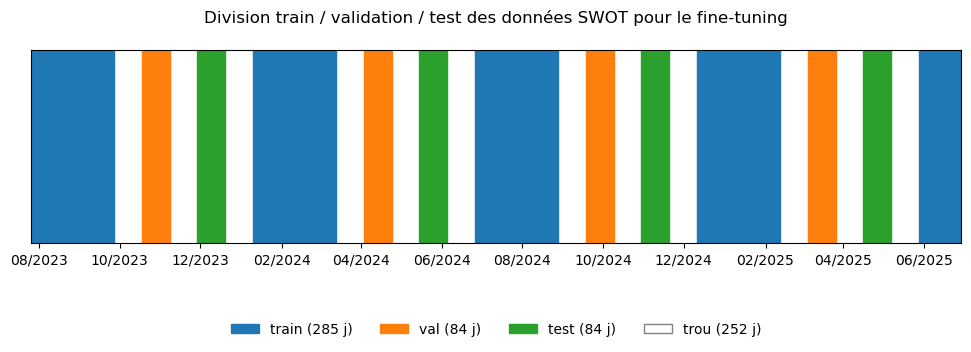

In [5]:
motif = [("train", 63), ("trou", 21), ("val", 21), ("trou", 21), ("test", 21), ("trou", 21)]
couleurs = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

# pour compter les jours de chaque jeu
jours = {"train": 0, "val": 0, "test": 0, "trou": 0}

fig, ax = plt.subplots(figsize=(12, 2.5))

# --- on avance bloc par bloc ---
date = debut
i = 0
while date <= fin:
    nom, duree = motif[i % len(motif)]          # bloc suivant du motif (on boucle)
    date_fin = min(date + pd.Timedelta(days=duree), fin + pd.Timedelta(days=1))

    if nom != "trou":                            # les trous restent blancs
        ax.axvspan(date, date_fin, color=couleurs[nom])

    jours[nom] += (date_fin - date).days
    date = date_fin
    i += 1


# --- légende avec le nombre de jours ---
legende = [Patch(color=couleurs[n], label=f"{n} ({jours[n]} j)") for n in couleurs]
legende.append(Patch(facecolor="white", edgecolor="grey", label=f"trou ({jours['trou']} j)"))
ax.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False)

# --- axes ---
ax.set_xlim(debut, fin)
ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("Division train / validation / test des données SWOT pour le fine-tuning", pad=20)

#plt.savefig("figures/division_dataset.png", dpi=200, bbox_inches="tight")
plt.show()